# Sleep Staging — 04: Classical Baseline Models and Feature Reduction

**Objetivo:** comparar modelos clásicos y distintas estrategias de reducción de dimensionalidad sobre las features tabulares generadas en la notebook anterior.

**Entrada principal:**
- `../data/processed/features_full.parquet`

**Experimentos:**

1. Todas las features.
2. Selección supervisada con ANOVA.
3. Selección supervisada con información mutua.
4. Reducción no supervisada con PCA.

**Modelos:**
- Dummy classifier.
- SGD Logistic.
- Random Forest.

La separación y la validación se realizan **por sujeto**. Toda transformación que utiliza información estadística o etiquetas se ajusta dentro de cada fold para evitar leakage.


---
## 0. Setup

Se limitan los threads nativos antes de importar NumPy y scikit-learn para reducir el riesgo de conflictos entre OpenBLAS, MKL y OpenMP.


In [1]:
import os

for variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[variable] = "1"

from pathlib import Path
from functools import partial
import gc
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import psutil

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from IPython.display import display, Image

from scipy.stats import kruskal

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import (
    SelectKBest,
    VarianceThreshold,
    f_classif,
    mutual_info_classif,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

# ── Rutas ─────────────────────────────────────────────────────
DATA_DIR = Path("../data/processed")
FIGURES_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../reports/results")

FEATURES_PATH = DATA_DIR / "features_full.parquet"
CV_RESULTS_PATH = RESULTS_DIR / "baseline_feature_reduction_cv.csv"
HOLDOUT_RESULTS_PATH = RESULTS_DIR / "baseline_holdout_metrics.json"
PREDICTIONS_PATH = RESULTS_DIR / "baseline_holdout_predictions.parquet"
MODEL_PATH = MODELS_DIR / "baseline_best_model.joblib"
KRUSKAL_PATH = RESULTS_DIR / "kruskal_feature_ranking.csv"

for directory in (FIGURES_DIR, MODELS_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# ── Parámetros ────────────────────────────────────────────────
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 3

ANOVA_K = 50
MI_K = 50
SELECTION_TOLERANCE = 0.005

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_ORDER = list(STAGE_MAP)
STAGE_NAMES = [STAGE_MAP[idx] for idx in STAGE_ORDER]

print("Setup completado.")
print("Threads numéricos limitados a 1.")


Setup completado.
Threads numéricos limitados a 1.


---
## 1. Carga y validación del dataset


In [ ]:
if not FEATURES_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo:\n{FEATURES_PATH.resolve()}\n"
        "Ejecutá primero la notebook 03 de feature engineering."
    )

features_df = pd.read_parquet(FEATURES_PATH)

METADATA_COLS = [
    "epoch_global",
    "epoch_in_subject",
    "label",
    "subject",
]

missing_metadata = [
    column
    for column in METADATA_COLS
    if column not in features_df.columns
]

if missing_metadata:
    raise ValueError(
        f"Faltan columnas de metadata: {missing_metadata}"
    )

FEATURE_COLS = [
    column
    for column in features_df.columns
    if column not in METADATA_COLS
]

X = features_df[FEATURE_COLS].astype(np.float32)
y = features_df["label"].astype(np.int8)
groups = features_df["subject"].astype(str)

assert len(X) == len(y) == len(groups)
assert set(y.unique()).issubset(STAGE_MAP)

print(f"Dataset:      {features_df.shape}")
print(f"Features:     {len(FEATURE_COLS)}")
print(f"Epochs:       {len(features_df)}")
print(f"Sujetos:      {groups.nunique()}")
print(f"Memoria:      {features_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")


Dataset:      (127904, 197)
Features:     193
Epochs:       127904
Sujetos:      151
Memoria:      100.2 MB


### 1.1 Distribución de clases


,epochs,percentage
label,,
W,19602,15.33
N1,13241,10.35
N2,48237,37.71
N3,26331,20.59
REM,20493,16.02


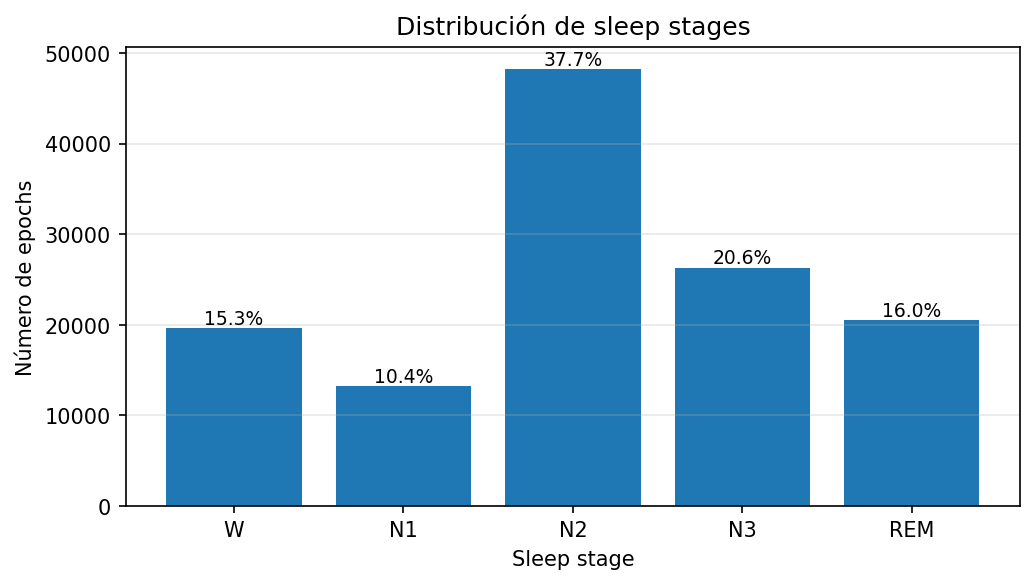

In [3]:
stage_summary = (
    y.value_counts()
    .sort_index()
    .rename(index=STAGE_MAP)
    .to_frame("epochs")
)

stage_summary["percentage"] = (
    100 * stage_summary["epochs"] / stage_summary["epochs"].sum()
)

display(stage_summary.round(2))

CLASS_DISTRIBUTION_PATH = FIGURES_DIR / "baseline_stage_distribution.png"

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(stage_summary.index, stage_summary["epochs"])

ax.set_title("Distribución de sleep stages")
ax.set_xlabel("Sleep stage")
ax.set_ylabel("Número de epochs")
ax.grid(axis="y", alpha=0.3)

for bar, percentage in zip(bars, stage_summary["percentage"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
    )

fig.tight_layout()
fig.savefig(
    CLASS_DISTRIBUTION_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(
        filename=str(CLASS_DISTRIBUTION_PATH),
        width=750,
    )
)


---
## 2. División por sujeto

Se reserva un conjunto final de sujetos no vistos. Todas las comparaciones de configuración se realizan únicamente sobre el conjunto de entrenamiento mediante `GroupKFold`.


In [4]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

train_subjects = set(groups_train.unique())
test_subjects = set(groups_test.unique())

assert train_subjects.isdisjoint(test_subjects)

print(f"Train epochs:     {len(X_train)}")
print(f"Test epochs:      {len(X_test)}")
print(f"Train sujetos:    {len(train_subjects)}")
print(f"Test sujetos:     {len(test_subjects)}")
print(f"Solapamiento:     {len(train_subjects & test_subjects)}")


Train epochs:     103338
Test epochs:      24566
Train sujetos:    120
Test sujetos:     31
Solapamiento:     0


In [5]:
# Liberar objetos que ya no se necesitan para la validación
del X
gc.collect()

process = psutil.Process(os.getpid())

print(f"RAM del kernel: {process.memory_info().rss / 1024**3:.2f} GB")
print(f"RAM disponible: {psutil.virtual_memory().available / 1024**3:.2f} GB")


RAM del kernel: 0.43 GB
RAM disponible: 14.74 GB


---
## 3. Análisis exploratorio no paramétrico

Kruskal–Wallis se usa únicamente como diagnóstico exploratorio. Para reducir la pseudorreplicación, el análisis se realiza sobre la media de cada feature por sujeto y stage, no sobre todos los epochs individuales.

Este ranking **no se utiliza directamente para entrenar los modelos**.


In [6]:
subject_stage_means = (
    features_df.loc[train_idx, ["subject", "label"] + FEATURE_COLS]
    .groupby(["subject", "label"], observed=True)[FEATURE_COLS]
    .mean()
    .reset_index()
)

kruskal_rows = []

for feature in FEATURE_COLS:
    stage_values = [
        group[feature].dropna().to_numpy()
        for _, group in subject_stage_means.groupby("label", observed=True)
    ]

    stage_values = [
        values for values in stage_values
        if len(values) > 0
    ]

    try:
        statistic, p_value = kruskal(*stage_values)
    except ValueError:
        statistic, p_value = np.nan, np.nan

    kruskal_rows.append({
        "feature": feature,
        "kruskal_h": statistic,
        "p_value": p_value,
    })

kruskal_df = (
    pd.DataFrame(kruskal_rows)
    .sort_values("kruskal_h", ascending=False)
    .reset_index(drop=True)
)

kruskal_df.to_csv(KRUSKAL_PATH, index=False)

display(kruskal_df.head(20).round(5))
print("Ranking guardado:", KRUSKAL_PATH.resolve())


,feature,kruskal_h,p_value
0,EEG C3-M2__beta_rel,424.310791,0.0
1,EEG C3-M2__ratio_sigma_beta,418.795166,0.0
2,EEG C3-M2__zcr,416.224121,0.0
3,EEG C4-M1__zcr,414.713654,0.0
4,EEG C4-M1__ratio_sigma_beta,410.972626,0.0
5,EEG C4-M1__std,403.725372,0.0
6,EEG C4-M1__rms,403.645996,0.0
7,EEG C4-M1__beta_rel,403.157227,0.0
8,EEG O2-M1__zcr,400.652374,0.0
9,EEG C4-M1__delta_abs,399.734375,0.0


Ranking guardado: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\kruskal_feature_ranking.csv


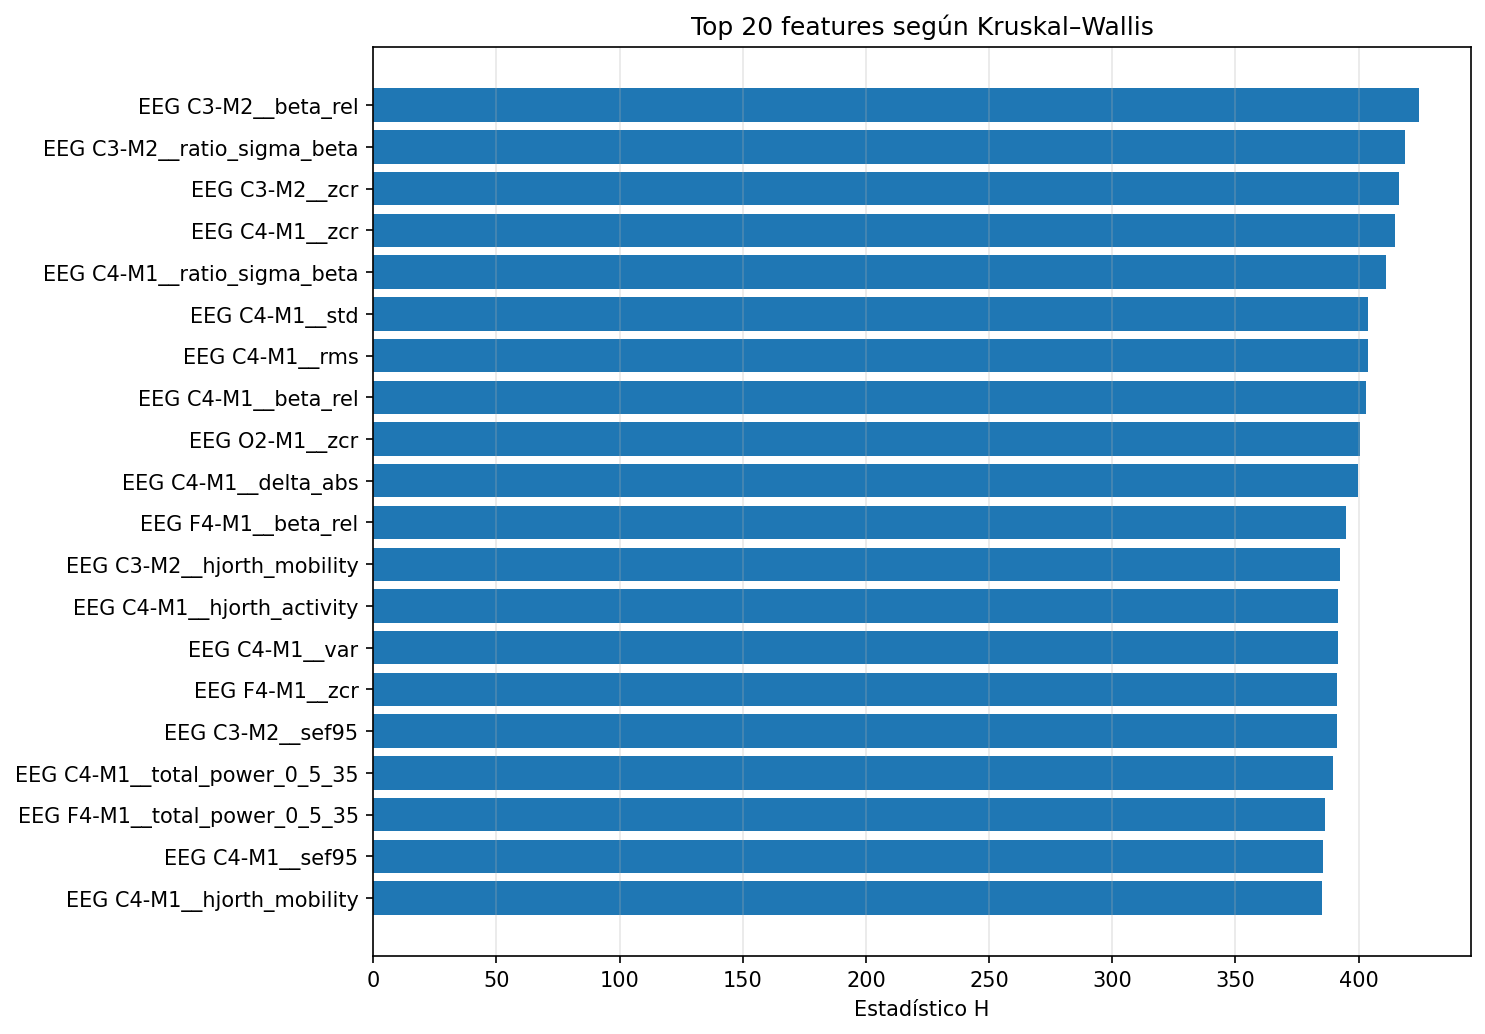

In [7]:
KRUSKAL_PLOT_PATH = FIGURES_DIR / "kruskal_top_features.png"

top_kruskal = (
    kruskal_df
    .dropna(subset=["kruskal_h"])
    .head(20)
    .sort_values("kruskal_h")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_kruskal["feature"],
    top_kruskal["kruskal_h"],
)

ax.set_title("Top 20 features según Kruskal–Wallis")
ax.set_xlabel("Estadístico H")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(
    KRUSKAL_PLOT_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(
        filename=str(KRUSKAL_PLOT_PATH),
        width=950,
    )
)


In [8]:
del subject_stage_means
gc.collect()


33

---
## 4. Pipelines y configuraciones

La imputación, el descarte de features constantes, la selección, el escalado y PCA se ajustan dentro de cada fold.

### Configuraciones comparadas

- Dummy con todas las features.
- SGD Logistic con todas las features.
- SGD Logistic con ANOVA top 50.
- SGD Logistic con información mutua top 50.
- SGD Logistic con PCA al 95% de varianza.
- Random Forest con todas las features.
- Random Forest con ANOVA top 50.

Chi-cuadrado no se utiliza porque las features son continuas y varias pueden tomar valores negativos.


In [9]:
def mutual_information_score(X_data, y_data):
    """Información mutua reproducible y con un solo thread."""
    return mutual_info_classif(
        X_data,
        y_data,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )

def make_sgd_pipeline(selector=None):
    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold(threshold=1e-12)),
    ]

    if selector is not None:
        steps.append(("selector", selector))

    steps.extend([
        ("scaler", StandardScaler()),
        (
            "model",
            SGDClassifier(
                loss="log_loss",
                penalty="l2",
                alpha=1e-4,
                max_iter=1000,
                tol=1e-3,
                class_weight="balanced",
                early_stopping=False,
                n_jobs=1,
                random_state=RANDOM_STATE,
            ),
        ),
    ])

    return Pipeline(steps)


def make_forest_pipeline(selector=None):
    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold(threshold=1e-12)),
    ]

    if selector is not None:
        steps.append(("selector", selector))

    steps.append(
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=20,
                min_samples_leaf=5,
                max_features="sqrt",
                class_weight="balanced_subsample",
                n_jobs=1,
                random_state=RANDOM_STATE,
            ),
        )
    )

    return Pipeline(steps)


experiments = {
    "Dummy | All features": DummyClassifier(
        strategy="most_frequent"
    ),
    "SGD | All features": make_sgd_pipeline(),
    "SGD | ANOVA top 50": make_sgd_pipeline(
        selector=SelectKBest(
            score_func=f_classif,
            k=min(ANOVA_K, len(FEATURE_COLS)),
        )
    ),
    "SGD | Mutual information top 50": make_sgd_pipeline(
        selector=SelectKBest(
            score_func=mutual_information_score,
            k=min(MI_K, len(FEATURE_COLS)),
        )
    ),
    "Random Forest | All features": make_forest_pipeline(),
    "Random Forest | ANOVA top 50": make_forest_pipeline(
        selector=SelectKBest(
            score_func=f_classif,
            k=min(ANOVA_K, len(FEATURE_COLS)),
        )
    ),
}

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro",
}

group_cv = GroupKFold(n_splits=N_SPLITS)

print("Configuraciones:")
for name in experiments:
    print(" -", name)


Configuraciones:
 - Dummy | All features
 - SGD | All features
 - SGD | ANOVA top 50
 - SGD | Mutual information top 50
 - Random Forest | All features
 - Random Forest | ANOVA top 50


---
## 5. Comparación con GroupKFold

Los experimentos se ejecutan secuencialmente. Los resultados se guardan después de cada configuración para no perder el progreso si una ejecución se interrumpe.


In [11]:
# Recuperar resultados ya guardados
if CV_RESULTS_PATH.exists():
    cv_results = pd.read_csv(CV_RESULTS_PATH)
    cv_rows = cv_results.to_dict("records")

    completed_experiments = set(
        cv_results["experiment"]
    )

    print("Resultados recuperados:")
    for experiment in completed_experiments:
        print(" -", experiment)

else:
    cv_rows = []
    completed_experiments = set()

for experiment_name, estimator in experiments.items():

    if experiment_name in completed_experiments:
        print(f"\nOmitiendo: {experiment_name}")
        print("Ya fue evaluado.")
        continue

    print(f"\nEvaluando: {experiment_name}")

    process = psutil.Process(os.getpid())

    print(
        f"RAM antes del ajuste: "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        groups=groups_train,
        cv=group_cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
    )

    row = {
        "experiment": experiment_name,
        "fit_time_mean": scores["fit_time"].mean(),
        "fit_time_std": scores["fit_time"].std(),
    }

    for metric in scoring:
        values = scores[f"test_{metric}"]

        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()

    cv_rows.append(row)

    cv_results = (
        pd.DataFrame(cv_rows)
        .sort_values(
            "f1_macro_mean",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    # Guardar inmediatamente
    cv_results.to_csv(
        CV_RESULTS_PATH,
        index=False,
    )

    print(
        f"Macro-F1: "
        f"{row['f1_macro_mean']:.4f} "
        f"± {row['f1_macro_std']:.4f}"
    )

    del scores
    gc.collect()

if not cv_rows:
    raise RuntimeError(
        "No hay resultados disponibles."
    )

cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values(
        "f1_macro_mean",
        ascending=False,
    )
    .drop_duplicates(
        subset="experiment",
        keep="last",
    )
    .reset_index(drop=True)
)

cv_results.to_csv(
    CV_RESULTS_PATH,
    index=False,
)

display(cv_results.round(4))

print(
    "Resultados guardados:",
    CV_RESULTS_PATH.resolve(),
)

Resultados recuperados:
 - SGD | All features
 - Dummy | All features
 - SGD | Mutual information top 50
 - SGD | ANOVA top 50

Omitiendo: Dummy | All features
Ya fue evaluado.

Omitiendo: SGD | All features
Ya fue evaluado.

Omitiendo: SGD | ANOVA top 50
Ya fue evaluado.

Omitiendo: SGD | Mutual information top 50
Ya fue evaluado.

Evaluando: Random Forest | All features
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.7098 ± 0.0129

Evaluando: Random Forest | ANOVA top 50
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.6887 ± 0.0124


,experiment,fit_time_mean,fit_time_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std
0,Random Forest | All features,185.6101,16.5301,0.7527,0.0108,0.7124,0.0092,0.7098,0.0129
1,SGD | All features,26.2356,6.3555,0.7520,0.0110,0.7187,0.0100,0.7092,0.0129
2,Random Forest | ANOVA top 50,101.0330,15.5669,0.7345,0.0119,0.6934,0.0089,0.6887,0.0124
3,SGD | ANOVA top 50,17.4028,0.5257,0.7232,0.0117,0.6778,0.0077,0.6687,0.0078
4,SGD | Mutual information top 50,239.6746,32.6415,0.7011,0.0156,0.6585,0.0166,0.6462,0.0212
5,Dummy | All features,0.0471,0.0040,0.3737,0.0253,0.2000,0.0000,0.1087,0.0054


Resultados guardados: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\baseline_feature_reduction_cv.csv


In [12]:
cv_rows = []

for experiment_name, estimator in experiments.items():
    print(f"\nEvaluando: {experiment_name}")

    process = psutil.Process(os.getpid())
    print(
        f"RAM antes del ajuste: "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        groups=groups_train,
        cv=group_cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
    )

    row = {
        "experiment": experiment_name,
        "fit_time_mean": scores["fit_time"].mean(),
        "fit_time_std": scores["fit_time"].std(),
    }

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()

    cv_rows.append(row)

    cv_results = (
        pd.DataFrame(cv_rows)
        .sort_values("f1_macro_mean", ascending=False)
        .reset_index(drop=True)
    )

    cv_results.to_csv(
        CV_RESULTS_PATH,
        index=False,
    )

    print(
        f"Macro-F1: "
        f"{row['f1_macro_mean']:.4f} "
        f"± {row['f1_macro_std']:.4f}"
    )

    del scores
    gc.collect()

if not cv_rows:
    raise RuntimeError("No se evaluó ninguna configuración.")

display(cv_results.round(4))
print("Resultados guardados:", CV_RESULTS_PATH.resolve())



Evaluando: Dummy | All features
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.1087 ± 0.0054

Evaluando: SGD | All features
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.7092 ± 0.0129

Evaluando: SGD | ANOVA top 50
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.6687 ± 0.0078

Evaluando: SGD | Mutual information top 50
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.6462 ± 0.0212

Evaluando: Random Forest | All features
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.7098 ± 0.0129

Evaluando: Random Forest | ANOVA top 50
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.6887 ± 0.0124


,experiment,fit_time_mean,fit_time_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std
0,Random Forest | All features,206.9649,18.3705,0.7527,0.0108,0.7124,0.0092,0.7098,0.0129
1,SGD | All features,33.2733,1.3327,0.7520,0.0110,0.7187,0.0100,0.7092,0.0129
2,Random Forest | ANOVA top 50,103.5692,3.9538,0.7345,0.0119,0.6934,0.0089,0.6887,0.0124
3,SGD | ANOVA top 50,11.0363,0.1139,0.7232,0.0117,0.6778,0.0077,0.6687,0.0078
4,SGD | Mutual information top 50,123.9546,2.3351,0.7011,0.0156,0.6585,0.0166,0.6462,0.0212
5,Dummy | All features,0.0732,0.0057,0.3737,0.0253,0.2000,0.0000,0.1087,0.0054


Resultados guardados: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\baseline_feature_reduction_cv.csv


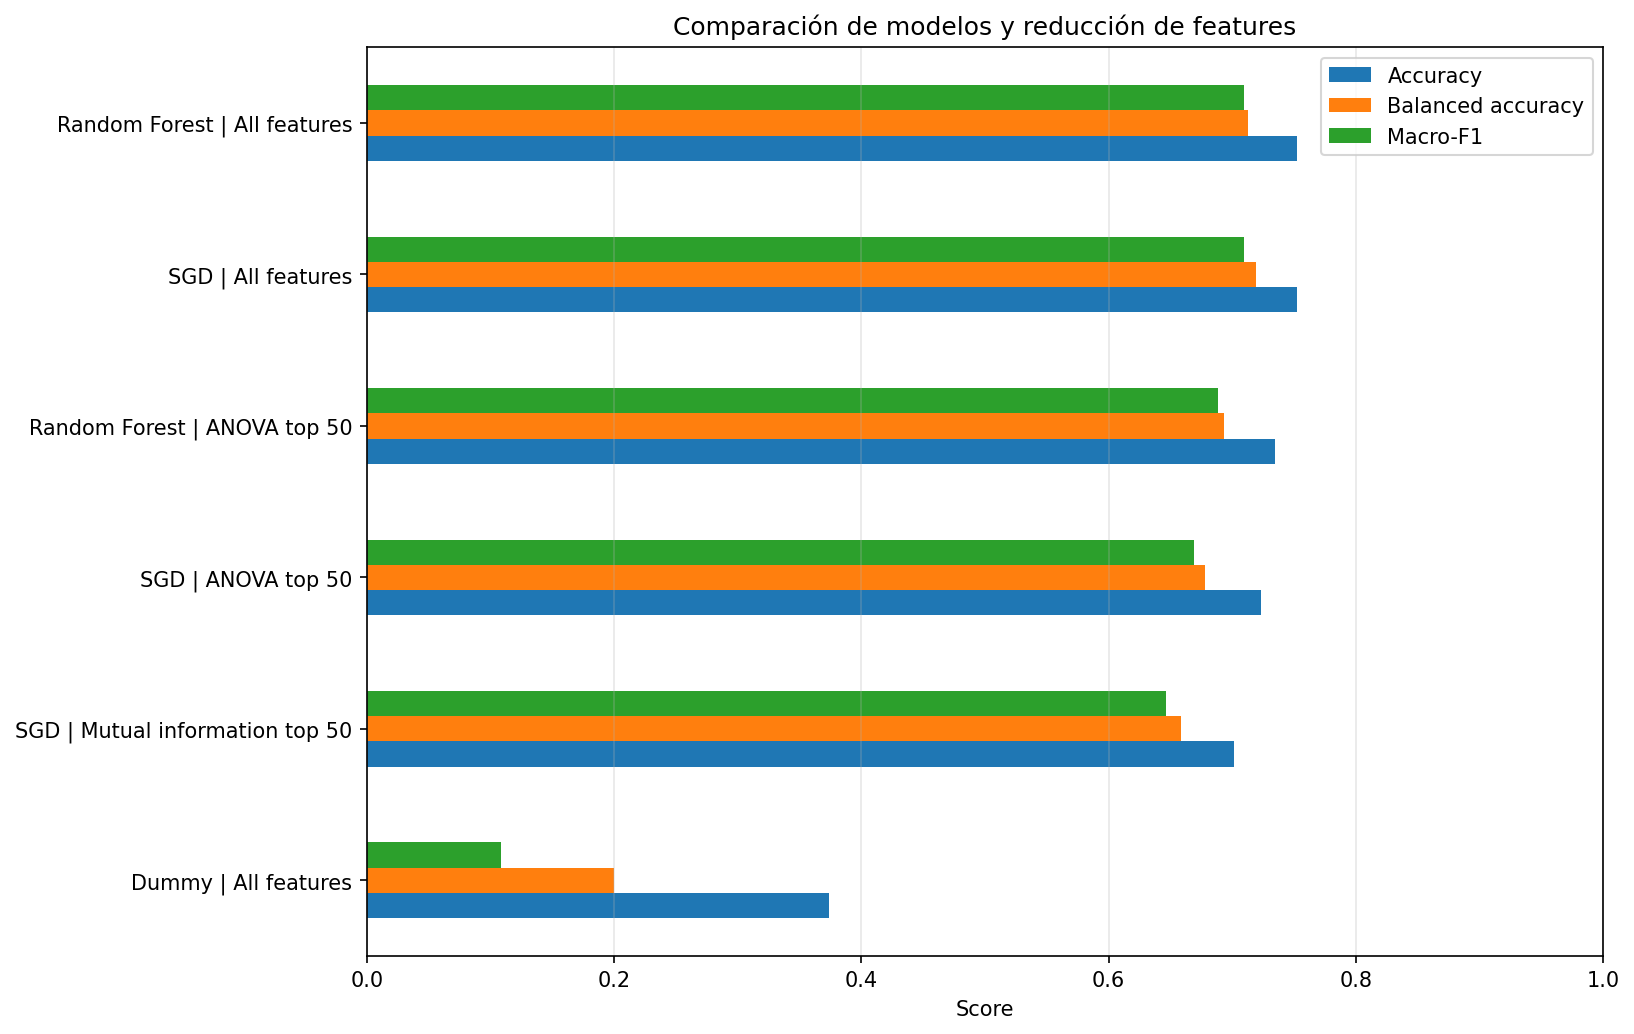

In [13]:
CV_PLOT_PATH = FIGURES_DIR / "feature_reduction_cv_comparison.png"

plot_df = (
    cv_results
    .set_index("experiment")[
        [
            "accuracy_mean",
            "balanced_accuracy_mean",
            "f1_macro_mean",
        ]
    ]
    .sort_values("f1_macro_mean")
)

fig, ax = plt.subplots(figsize=(11, 7))
plot_df.plot(kind="barh", ax=ax)

ax.set_title("Comparación de modelos y reducción de features")
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.3)
ax.legend([
    "Accuracy",
    "Balanced accuracy",
    "Macro-F1",
])

fig.tight_layout()
fig.savefig(
    CV_PLOT_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(
        filename=str(CV_PLOT_PATH),
        width=1050,
    )
)


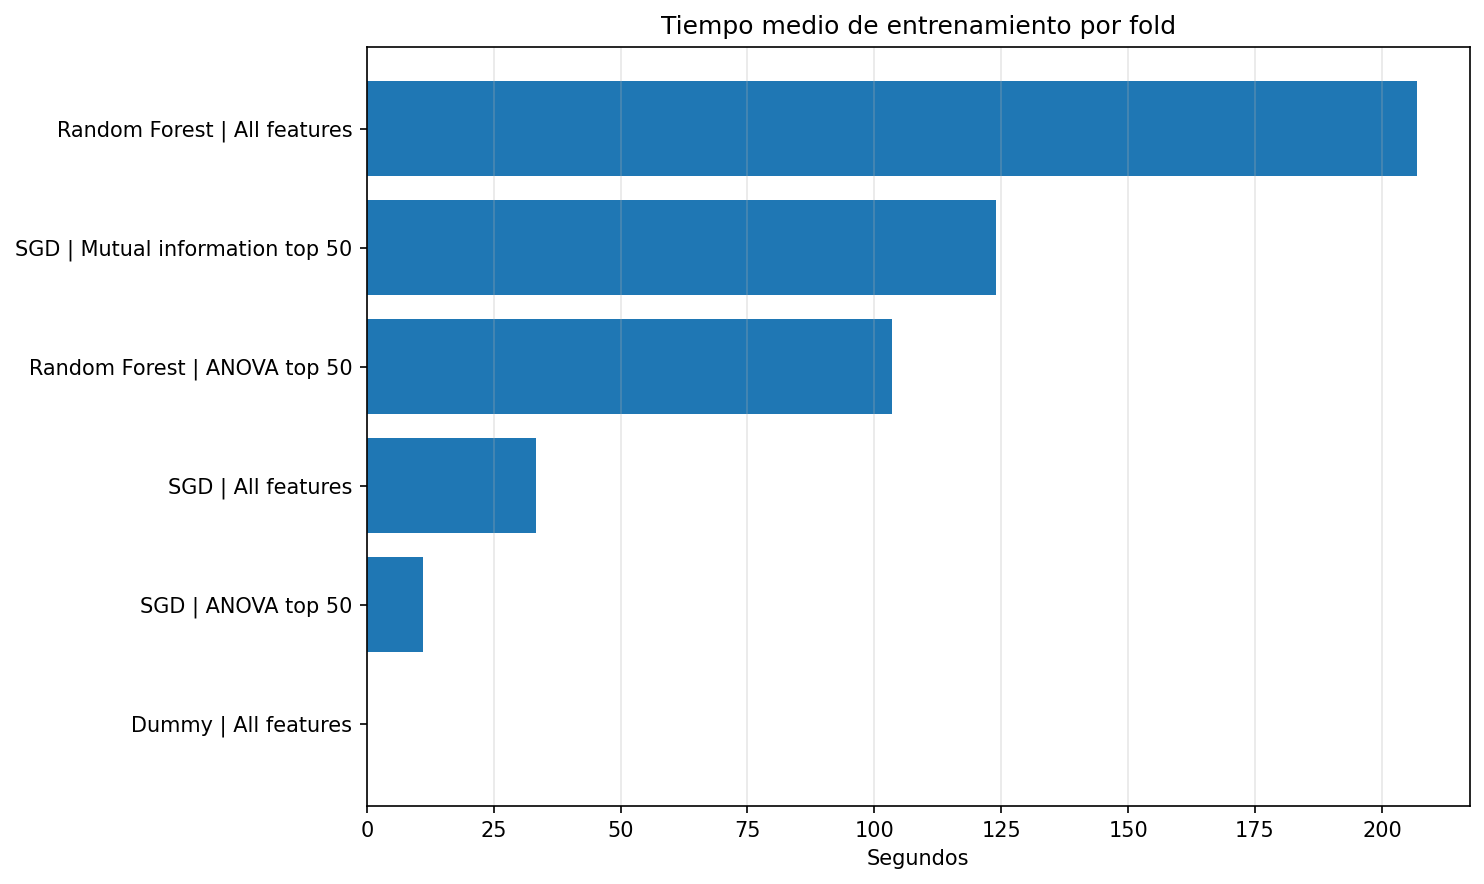

In [14]:
TIME_PLOT_PATH = FIGURES_DIR / "feature_reduction_fit_time.png"

time_df = (
    cv_results[
        ["experiment", "fit_time_mean"]
    ]
    .sort_values("fit_time_mean")
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    time_df["experiment"],
    time_df["fit_time_mean"],
)

ax.set_title("Tiempo medio de entrenamiento por fold")
ax.set_xlabel("Segundos")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(
    TIME_PLOT_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(
        filename=str(TIME_PLOT_PATH),
        width=950,
    )
)


---
## 6. Selección y entrenamiento final

Si varias configuraciones quedan dentro de 0.005 de Macro-F1 respecto del máximo, se prioriza la alternativa más simple e interpretable.


In [15]:
best_f1 = cv_results["f1_macro_mean"].max()

competitive = cv_results[
    cv_results["f1_macro_mean"] >= best_f1 - SELECTION_TOLERANCE
]

preferred_order = [
    "SGD | ANOVA top 50",
    "SGD | All features",
    "SGD | Mutual information top 50",
    "SGD | PCA 95%",
    "Random Forest | ANOVA top 50",
    "Random Forest | All features",
    "Dummy | All features",
]

best_experiment_name = next(
    name
    for name in preferred_order
    if name in competitive["experiment"].values
)

best_model = clone(
    experiments[best_experiment_name]
)

print("Mejor Macro-F1:", round(best_f1, 4))
print("Configuraciones competitivas:")
display(competitive.round(4))

print("Configuración seleccionada:", best_experiment_name)

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)


Mejor Macro-F1: 0.7098
Configuraciones competitivas:


,experiment,fit_time_mean,fit_time_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std
0,Random Forest | All features,206.9649,18.3705,0.7527,0.0108,0.7124,0.0092,0.7098,0.0129
1,SGD | All features,33.2733,1.3327,0.7520,0.0110,0.7187,0.0100,0.7092,0.0129


Configuración seleccionada: SGD | All features


In [16]:
holdout_metrics = {
    "experiment": best_experiment_name,
    "accuracy": float(
        accuracy_score(y_test, y_pred)
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_pred)
    ),
    "f1_macro": float(
        f1_score(y_test, y_pred, average="macro")
    ),
    "n_train_epochs": int(len(X_train)),
    "n_test_epochs": int(len(X_test)),
    "n_train_subjects": int(len(train_subjects)),
    "n_test_subjects": int(len(test_subjects)),
}

display(
    pd.Series(holdout_metrics)
    .to_frame("value")
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=STAGE_ORDER,
        target_names=STAGE_NAMES,
        digits=4,
        zero_division=0,
    )
)


,value
experiment,SGD | All features
accuracy,0.76614
balanced_accuracy,0.739709
f1_macro,0.72986
n_train_epochs,103338
n_test_epochs,24566
n_train_subjects,120
n_test_subjects,31



Classification report:
              precision    recall  f1-score   support

           W     0.7689    0.8698    0.8162      3409
          N1     0.4628    0.3667    0.4091      2831
          N2     0.8155    0.7818    0.7983      9617
          N3     0.8282    0.8113    0.8196      4663
         REM     0.7514    0.8690    0.8060      4046

    accuracy                         0.7661     24566
   macro avg     0.7254    0.7397    0.7299     24566
weighted avg     0.7602    0.7661    0.7613     24566



### 6.1 Matriz de confusión


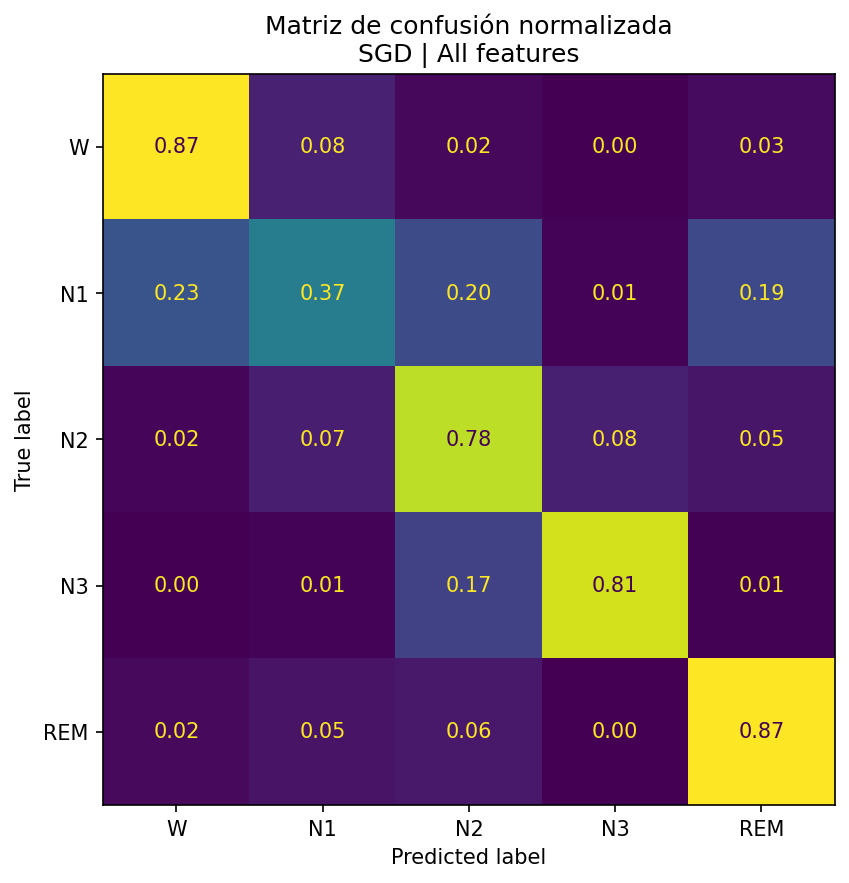

In [17]:
CONFUSION_PATH = FIGURES_DIR / "baseline_holdout_confusion_matrix.png"

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=STAGE_ORDER,
    normalize="true",
)

fig, ax = plt.subplots(figsize=(7, 6))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=STAGE_NAMES,
)

display_cm.plot(
    ax=ax,
    values_format=".2f",
    colorbar=False,
)

ax.set_title(
    f"Matriz de confusión normalizada\n{best_experiment_name}"
)

fig.tight_layout()
fig.savefig(
    CONFUSION_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(
        filename=str(CONFUSION_PATH),
        width=700,
    )
)


---
## 7. Interpretación del modelo seleccionado


In [18]:
def transformed_feature_names(fitted_pipeline, original_features):
    """Recupera nombres luego de varianza y selección."""
    names = np.asarray(original_features)

    variance_step = fitted_pipeline.named_steps.get("variance")
    if variance_step is not None:
        names = names[variance_step.get_support()]

    selector_step = fitted_pipeline.named_steps.get("selector")
    if selector_step is not None:
        names = names[selector_step.get_support()]

    return names


def importance_table(fitted_pipeline, original_features):
    """Importancia para SGD y Random Forest sin PCA."""
    if "pca" in fitted_pipeline.named_steps:
        return None

    estimator = fitted_pipeline.named_steps["model"]
    names = transformed_feature_names(
        fitted_pipeline,
        original_features,
    )

    if hasattr(estimator, "feature_importances_"):
        importance = estimator.feature_importances_

    elif hasattr(estimator, "coef_"):
        importance = np.abs(estimator.coef_).mean(axis=0)

    else:
        return None

    return (
        pd.DataFrame({
            "feature": names,
            "importance": importance,
        })
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )


importance_df = importance_table(
    best_model,
    FEATURE_COLS,
)

if importance_df is None:
    print(
        "La configuración seleccionada usa PCA o no expone "
        "importancia directa de las features originales."
    )
else:
    display(importance_df.head(20))


,feature,importance
0,EEG C3-M2__ratio_sigma_beta,1.048045
1,EEG C4-M1__ratio_delta_beta,1.010975
2,EEG C4-M1__spectral_entropy,0.977257
3,EEG C3-M2__spectral_entropy,0.879517
4,EEG O2-M1__delta_rel,0.863833
5,EEG C3-M2__beta_rel,0.859070
6,EEG O2-M1__hjorth_mobility,0.831840
7,EEG C4-M1__delta_rel,0.800460
8,EMG chin__power_20_35_rel,0.794652
9,EEG F4-M1__hjorth_mobility,0.725391


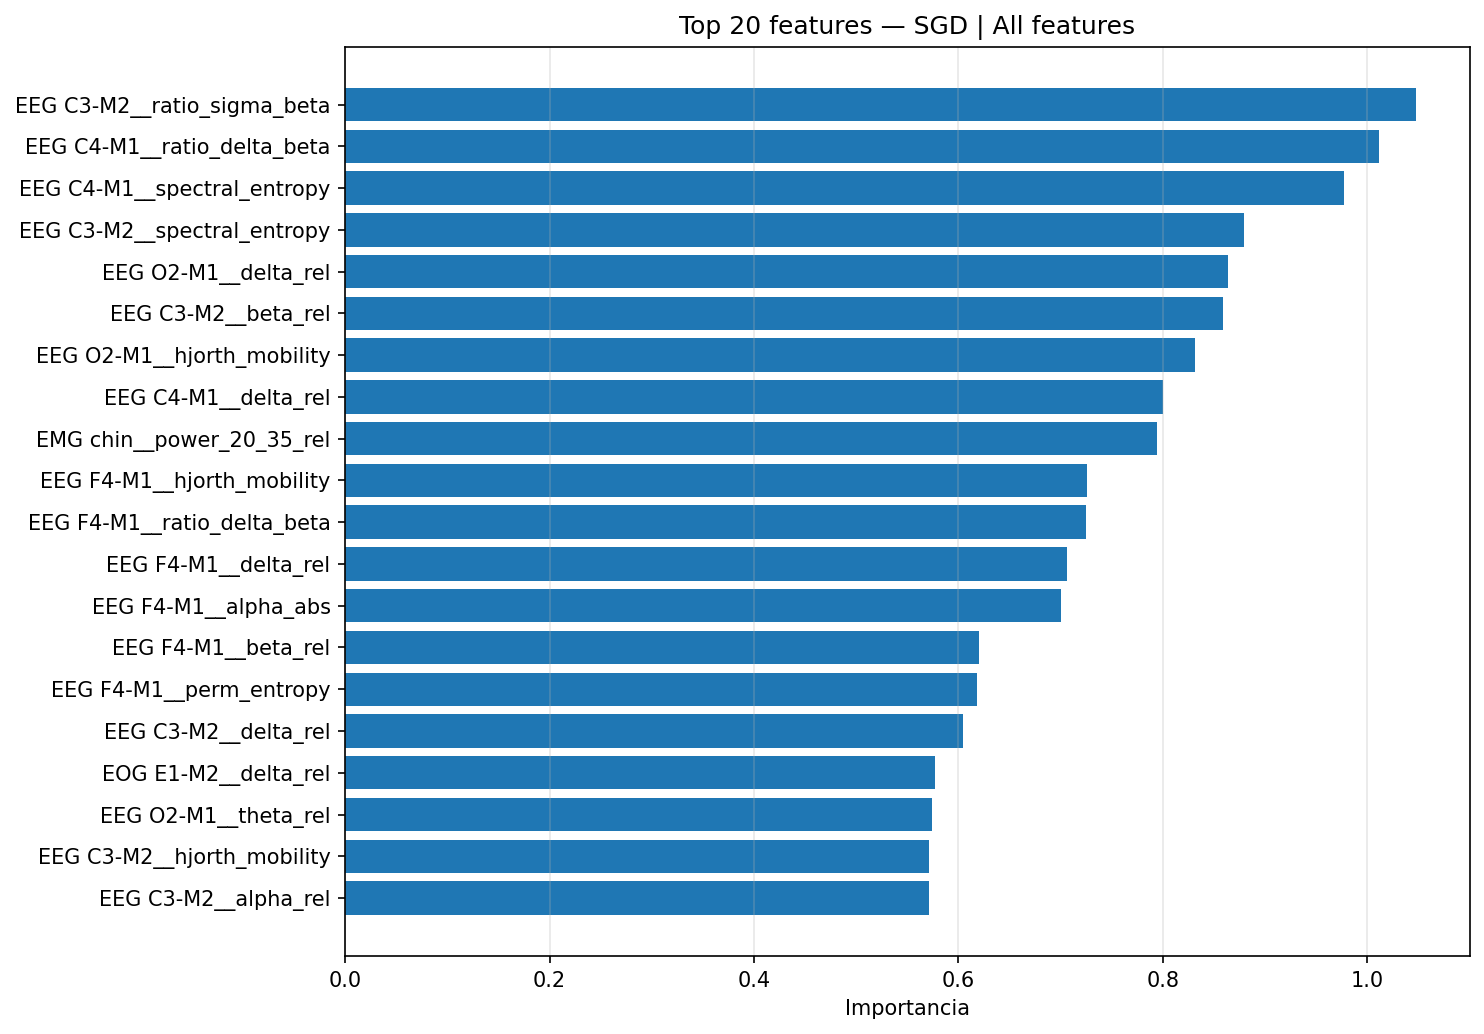

In [19]:
if importance_df is not None:
    IMPORTANCE_PATH = FIGURES_DIR / "baseline_feature_importance.png"

    top_importance = (
        importance_df
        .head(20)
        .sort_values("importance")
    )

    fig, ax = plt.subplots(figsize=(10, 7))

    ax.barh(
        top_importance["feature"],
        top_importance["importance"],
    )

    ax.set_title(
        f"Top 20 features — {best_experiment_name}"
    )
    ax.set_xlabel("Importancia")
    ax.grid(axis="x", alpha=0.3)

    fig.tight_layout()
    fig.savefig(
        IMPORTANCE_PATH,
        dpi=150,
        bbox_inches="tight",
    )
    plt.close(fig)

    display(
        Image(
            filename=str(IMPORTANCE_PATH),
            width=950,
        )
    )


---
## 8. Guardado de artefactos


In [20]:
joblib.dump(
    {
        "model": best_model,
        "feature_names": FEATURE_COLS,
        "stage_map": STAGE_MAP,
        "experiment": best_experiment_name,
    },
    MODEL_PATH,
)

predictions_df = features_df.iloc[test_idx][
    METADATA_COLS
].copy()

predictions_df["y_true"] = y_test.to_numpy()
predictions_df["y_pred"] = y_pred

predictions_df.to_parquet(
    PREDICTIONS_PATH,
    index=False,
)

with open(
    HOLDOUT_RESULTS_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        holdout_metrics,
        file,
        indent=2,
        ensure_ascii=False,
    )

print("Modelo:", MODEL_PATH.resolve())
print("Predicciones:", PREDICTIONS_PATH.resolve())
print("Métricas:", HOLDOUT_RESULTS_PATH.resolve())


Modelo: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\models\baseline_best_model.joblib
Predicciones: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\baseline_holdout_predictions.parquet
Métricas: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\baseline_holdout_metrics.json


---
## 9. Checklist final


In [21]:
checks = {
    "Sin solapamiento de sujetos": (
        train_subjects.isdisjoint(test_subjects)
    ),
    "Cross-validation guardada": CV_RESULTS_PATH.exists(),
    "Ranking Kruskal guardado": KRUSKAL_PATH.exists(),
    "Modelo guardado": MODEL_PATH.exists(),
    "Predicciones guardadas": PREDICTIONS_PATH.exists(),
    "Métricas guardadas": HOLDOUT_RESULTS_PATH.exists(),
    "Predicciones alineadas": len(y_pred) == len(y_test),
}

print("=" * 72)
print("CHECKLIST — BASELINE Y REDUCCIÓN DE FEATURES")
print("=" * 72)

for label, passed in checks.items():
    print(f"{'✅' if passed else '❌'}  {label}")

print("\nResumen:")
print(f"  configuración:       {best_experiment_name}")
print(f"  holdout accuracy:    {holdout_metrics['accuracy']:.4f}")
print(f"  balanced accuracy:   {holdout_metrics['balanced_accuracy']:.4f}")
print(f"  holdout macro-F1:    {holdout_metrics['f1_macro']:.4f}")

print("\nPróximo paso:")
print("  Probar modelos de boosting bajo el mismo split por sujeto.")


CHECKLIST — BASELINE Y REDUCCIÓN DE FEATURES
✅  Sin solapamiento de sujetos
✅  Cross-validation guardada
✅  Ranking Kruskal guardado
✅  Modelo guardado
✅  Predicciones guardadas
✅  Métricas guardadas
✅  Predicciones alineadas

Resumen:
  configuración:       SGD | All features
  holdout accuracy:    0.7661
  balanced accuracy:   0.7397
  holdout macro-F1:    0.7299

Próximo paso:
  Probar modelos de boosting bajo el mismo split por sujeto.
